# Homework07

Exercises to practice pandas, data analysis and regression

## Goals

- Understand the effects of pre-processing data
- Get familiar with the ML flow: encode -> normalize -> train -> evaluate
- Understand the difference between regression and classification tasks
- Build intuition for different regression models

### Setup

Run the following 2 cells to import all necessary libraries and helpers for this homework.

In [1]:
# !wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py# !wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py
# My Note: I ran out of the free usage of the GitHub Codespaces, I need to use VSCode to complete homeworks locally on my MacBook. Thus I will do some environment deployment for my VSCode.

!curl -L -s "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -o data_utils.py

In [2]:
# My Note: Install library for this Python 3.13 Environment.

%pip install pandas matplotlib scikit-learn librosa ipykernel

Note: you may need to restart the kernel to use updated packages.


In [3]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, SGDRegressor

from data_utils import object_from_json_url
from data_utils import regression_error

### Load Dataset

Let's load up the full [ANSUR](https://www.openlab.psu.edu/ansur2/) dataset that we looked at briefly in [Week 02](https://github.com/DM-GY-9103-2024F-H/WK02).

This is the dataset that has anthropometric information about U.S. Army personnel.

#### WARNING

Like we mentioned in class, this dataset is being used for these exercises due to the level of detail in the dataset and the rigorous process that was used in collecting the data.

This is a very specific dataset and should not be used to draw general conclusions about people, bodies, or anything else that is not related to the distribution of physical features of U.S. Army personnel.

In [4]:
# Load Dataset
ANSUR_FILE = "https://raw.githubusercontent.com/PSAM-5020-2026F-A/5020-utils/main/datasets/json/ansur.json"
ansur_data = object_from_json_url(ANSUR_FILE)

# Look at first 2 records
ansur_data[:2]

[{'age': 18,
  'gender': 'F',
  'height': 66,
  'weight': 135,
  'span': 1699,
  'stature': 1645,
  'ear': {'breadth': 30, 'length': 61, 'protrusion': 20},
  'foot': {'breadth': 97, 'length': 243},
  'hand': {'breadth': 78, 'length': 182, 'palm': 108},
  'head': {'height': 243, 'circumference': 557}},
 {'age': 30,
  'gender': 'M',
  'height': 68,
  'weight': 207,
  'span': 1749,
  'stature': 1715,
  'ear': {'breadth': 35, 'length': 63, 'protrusion': 17},
  'foot': {'breadth': 100, 'length': 252},
  'hand': {'breadth': 87, 'length': 184, 'palm': 114},
  'head': {'height': 238, 'circumference': 560}}]

#### Nested data

This is that *nested* dataset from Week 02.

# 🤔

Let's load it into a `DataFrame` to see what happens.

In [5]:
# Read into DataFrame
ansur_df = pd.DataFrame.from_records(ansur_data)
ansur_df.head()

,age,gender,height,weight,span,stature,ear,foot,hand,head
0,18,F,66,135,1699,1645,"{'breadth': 30, 'length': 61, 'protrusion': 20}","{'breadth': 97, 'length': 243}","{'breadth': 78, 'length': 182, 'palm': 108}","{'height': 243, 'circumference': 557}"
1,30,M,68,207,1749,1715,"{'breadth': 35, 'length': 63, 'protrusion': 17}","{'breadth': 100, 'length': 252}","{'breadth': 87, 'length': 184, 'palm': 114}","{'height': 238, 'circumference': 560}"
2,27,M,67,121,1684,1657,"{'breadth': 36, 'length': 59, 'protrusion': 24}","{'breadth': 92, 'length': 251}","{'breadth': 84, 'length': 180, 'palm': 103}","{'height': 239, 'circumference': 516}"
3,20,M,73,185,1878,1828,"{'breadth': 36, 'length': 60, 'protrusion': 21}","{'breadth': 104, 'length': 280}","{'breadth': 95, 'length': 201, 'palm': 124}","{'height': 270, 'circumference': 582}"
4,33,M,76,150,1977,1883,"{'breadth': 39, 'length': 65, 'protrusion': 27}","{'breadth': 101, 'length': 271}","{'breadth': 90, 'length': 194, 'palm': 113}","{'height': 254, 'circumference': 559}"



# 😓🙄

That didn't work too well. We ended up with objects in our columns.

Luckily, our `DataFrame` library has a function called [`json_normalize()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.json_normalize.html) that can help.

In [6]:
# Read into DataFrame
ansur_df = pd.json_normalize(ansur_data)
ansur_df.head()

,age,gender,height,weight,span,stature,ear.breadth,ear.length,ear.protrusion,foot.breadth,foot.length,hand.breadth,hand.length,hand.palm,head.height,head.circumference
0,18,F,66,135,1699,1645,30,61,20,97,243,78,182,108,243,557
1,30,M,68,207,1749,1715,35,63,17,100,252,87,184,114,238,560
2,27,M,67,121,1684,1657,36,59,24,92,251,84,180,103,239,516
3,20,M,73,185,1878,1828,36,60,21,104,280,95,201,124,270,582
4,33,M,76,150,1977,1883,39,65,27,101,271,90,194,113,254,559


Much better. `DataFrames` are magic.

#### Data Exploration

Before we start creating models, let's do a little bit of data analysis and get a feeling for the shapes, distributions and relationships of our data.

1. Print `min`, `max` and `average` values for all of the features.
2. Print `covariance` tables for `age`, `ear.length` and `head.circumference`.
3. Plot `age`, `ear.length` and `head.circumference` versus the $1$ *feature* that is most correlated to each of them.

Don't forget to *encode* and *normalize* the data.

age                     17.0
gender                   0.0
height                  56.0
weight                   0.0
span                  1323.0
stature               1409.0
ear.breadth             25.0
ear.length              46.0
ear.protrusion          13.0
foot.breadth            77.0
foot.length            198.0
hand.breadth            67.0
hand.length            145.0
hand.palm               88.0
head.height            206.0
head.circumference     502.0
dtype: float64
age                     58.0
gender                   1.0
height                  94.0
weight                 321.0
span                  2121.0
stature               1993.0
ear.breadth             46.0
ear.length              81.0
ear.protrusion          34.0
foot.breadth           126.0
foot.length            323.0
hand.breadth           105.0
hand.length            239.0
hand.palm              140.0
head.height            295.0
head.circumference     635.0
dtype: float64
age                     29.745357
gender  

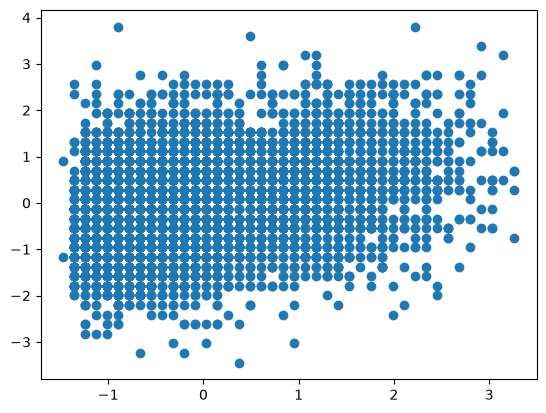

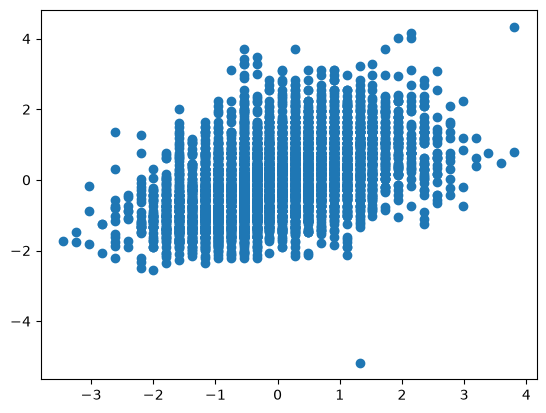

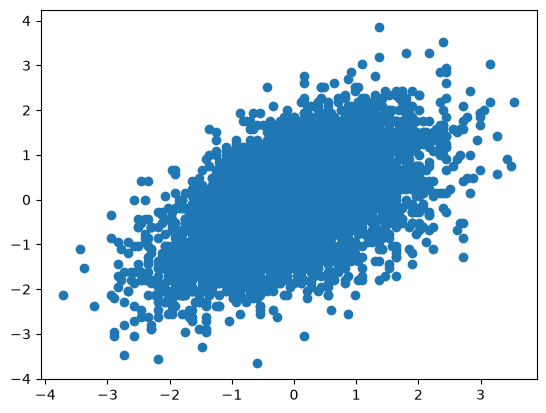

In [7]:
# Work on Data Exploration here

### Encode non-numerical features
# My note: According to the diagram listed below the previous code cell, the only non-numeric feature is gender. So I should encode gender data.

ansur_encoder = OrdinalEncoder() # My Note: According to the dataset I loaded above, I need to build an Encoder for this project to count values.

# My Note: This sentence is to make sure the original gender values (which are non-numerical values) to be transformed into numberic values.
gender_values = ansur_encoder.fit_transform(ansur_df[["gender"]])

# My Note: Let the transformed gender values to be the final version of the gender values, which are used to replace the non-numeric version listed above.
ansur_df[["gender"]] = gender_values

## 1. Print min, max, avg
# My Note: According to the Web3Schools Pandas Library, the average value is written as average (mean) value, which is mean().
print(ansur_df.min())
print(ansur_df.max())
print(ansur_df.mean())

### Normalize all data

# My Note: Let ansur_scaler to be the standard dimension for all data in the training dataset.
ansur_scaler = StandardScaler()

# My Note: Let the scaled data to be the final version of the data, replacing the original version that vary from different numeric scales.
scaled_values = ansur_scaler.fit_transform(ansur_df)
# My Note: After claiming the scaled data, I need to put them back to the list that have column names. 
ansur_scaled_df = pd.DataFrame(scaled_values, columns = ansur_df.columns)

## 2. Print Covariances
# My Note: Let the covariance has a value.
covariance_df = ansur_scaled_df.cov()
print(covariance_df[["age", "ear.length", "head.circumference"]])

## 3. Plot features most correlated to age, ear length and head circumference
# My Note: According to the 3rd row of the requirement for this cell, I need to find out the feature that each most correlated with age, ear length, and head circumference, and create a scattered diagram.
plt.scatter(ansur_scaled_df[["age"]], ansur_scaled_df[["ear.length"]])
plt.show()

plt.scatter(ansur_scaled_df[["ear.length"]], ansur_scaled_df[["weight"]])
plt.show()

plt.scatter(ansur_scaled_df[["head.circumference"]], ansur_scaled_df[["head.height"]])
plt.show()


### Interpretation

<span style="color:hotpink;">
Does anything stand out about these graphs? Or the correlations?<br>
Are correlations symmetric? Does the feature most correlated to ear length also have ear length as its most correlated pair?
</span>

#### My Answer
<span style = "color: orange">
After completing this section, I learned how to read the covariance data lists. <br>
To get the largest number from each column, we need to exlude the variances, which are: age versus age, ear lengh versus ear length, and head circumference versus head circumference. Their values are all 1.000179. <br>
Thus we can know that: Ear length is most correlated to age, I think it reflects the reality that when people getting older, their ears are longer than before. Secondly, the weight is most correlated to ear length. Thirdly, the head height is most correlated to head circumference.<br>
<br>
The covariance itself is symmetric, the value of age versus ear length is same with ear length versus age. <br>
But "the most correlated pair" are not symmetric, the most correlated feature to age is ear length, but the most correlated feature to ear length is weight.
</span>


<span style="color:hotpink;">EDIT THIS CELL WITH ANSWER</span>

### Regression

Now, we want to create a regression model to predict `head.circumference` from the data.

From our [Week 07](https://github.com/PSAM-5020-2026F-A/WK07) notebook, we can create a regression model by following these steps:

1. Load dataset (done! 🎉)
2. Encode label features as numbers (done! ⚡️)
3. Normalize the data (done! 🍾)
4. Separate the outcome variable and the input features
5. Create a regression model using all features
6. Run model on training data and measure error
7. Plot predictions and interpret results
8. Run model on test data, measure error, plot predictions, interpret results

0.7584338370549019


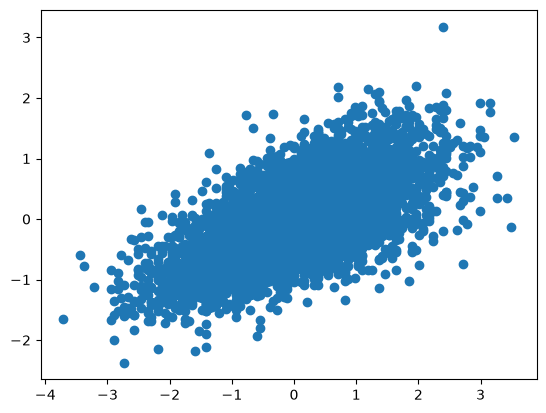

In [8]:
# Work on Regression Model here

## Separate outcome variable and input features
# My Note: Let the circumference values have the values based on the scaled values from previous section.
circumference_values = ansur_scaled_df[["head.circumference"]]
# My Note: Exclude the column that contains head.circumference data.
feature_values = ansur_scaled_df.drop(columns = ["head.circumference"])

## Create a regression model to predict head.circumference data.
ansur_model = LinearRegression()
ansur_model.fit(feature_values, circumference_values)

## Measure error on training data
# My Note: Let the predict_values to have values from ansur model that created above
predict_values = ansur_model.predict(feature_values)
print(regression_error(circumference_values, predict_values))

## Plot predictions and interpret results
plt.scatter(circumference_values, predict_values)
plt.show()

In [9]:
## Load Test Data
ANSUR_TEST_FILE = "https://raw.githubusercontent.com/PSAM-5020-2026F-A/5020-utils/main/datasets/json/ansur-test.json"

ansur_test_data = object_from_json_url(ANSUR_TEST_FILE)
ansur_test_df = pd.json_normalize(ansur_test_data)

ansur_test_encoded_df = ansur_test_df.copy()

g_vals = ansur_encoder.transform(ansur_test_df[["gender"]])
ansur_test_encoded_df[["gender"]] = g_vals

ansur_test_scaled_df = ansur_scaler.transform(ansur_test_encoded_df)

0.7891115826821989


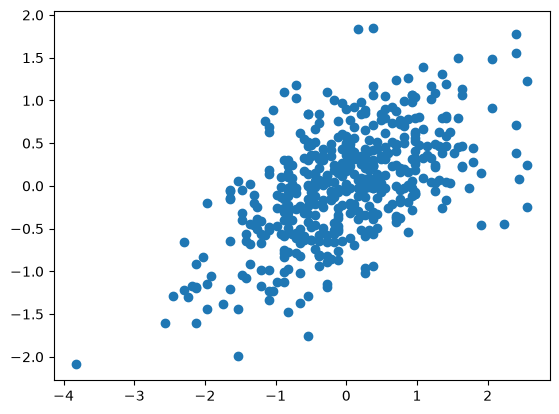

In [12]:
## Run model on test data

# My Note: Bring the test data back to the named column
ansur_test_scaled_df = pd.DataFrame(ansur_test_scaled_df, columns = ansur_test_encoded_df.columns)
# Seperate out the data that need to be tested
test_circumference_values = ansur_test_scaled_df[["head.circumference"]]
# Exclude the column that contains head.circumference data
test_feature_values = ansur_test_scaled_df.drop(columns = ["head.circumference"])
test_predict_values = ansur_model.predict(test_feature_values)

## Measure error on test data
print(regression_error(test_circumference_values, test_predict_values))

## Plot predictions and interpret results
plt.scatter(test_circumference_values, test_predict_values)
plt.show()


### Interpretation

<span style="color:hotpink;">
How well does your model perform?<br>
How could you improve it?<br>
Are there ranges of circumferences that don't get predicted well?
</span>

<span style="color:hotpink;">EDIT THIS CELL WITH ANSWER</span>